In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from heart_risk.data import TARGET, load_clean

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:
display(df.describe().T)
missing = df.isna().sum()
display(missing[missing > 0].to_frame("missing")
        .assign(pct=lambda m: (m["missing"] / len(df) * 100).round(2)))

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


,missing,pct
ca,4,1.32
thal,2,0.66


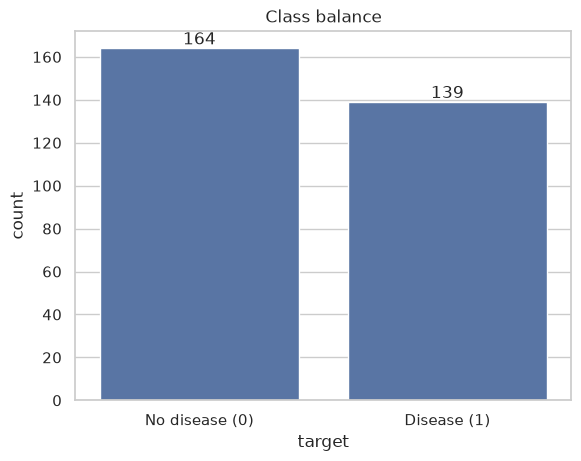

target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [4]:
ax = sns.countplot(data=df, x=TARGET)
ax.set_xticks([0, 1], ["No disease (0)", "Disease (1)"])
ax.bar_label(ax.containers[0])
ax.set_title("Class balance")
plt.savefig(FIG_DIR / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

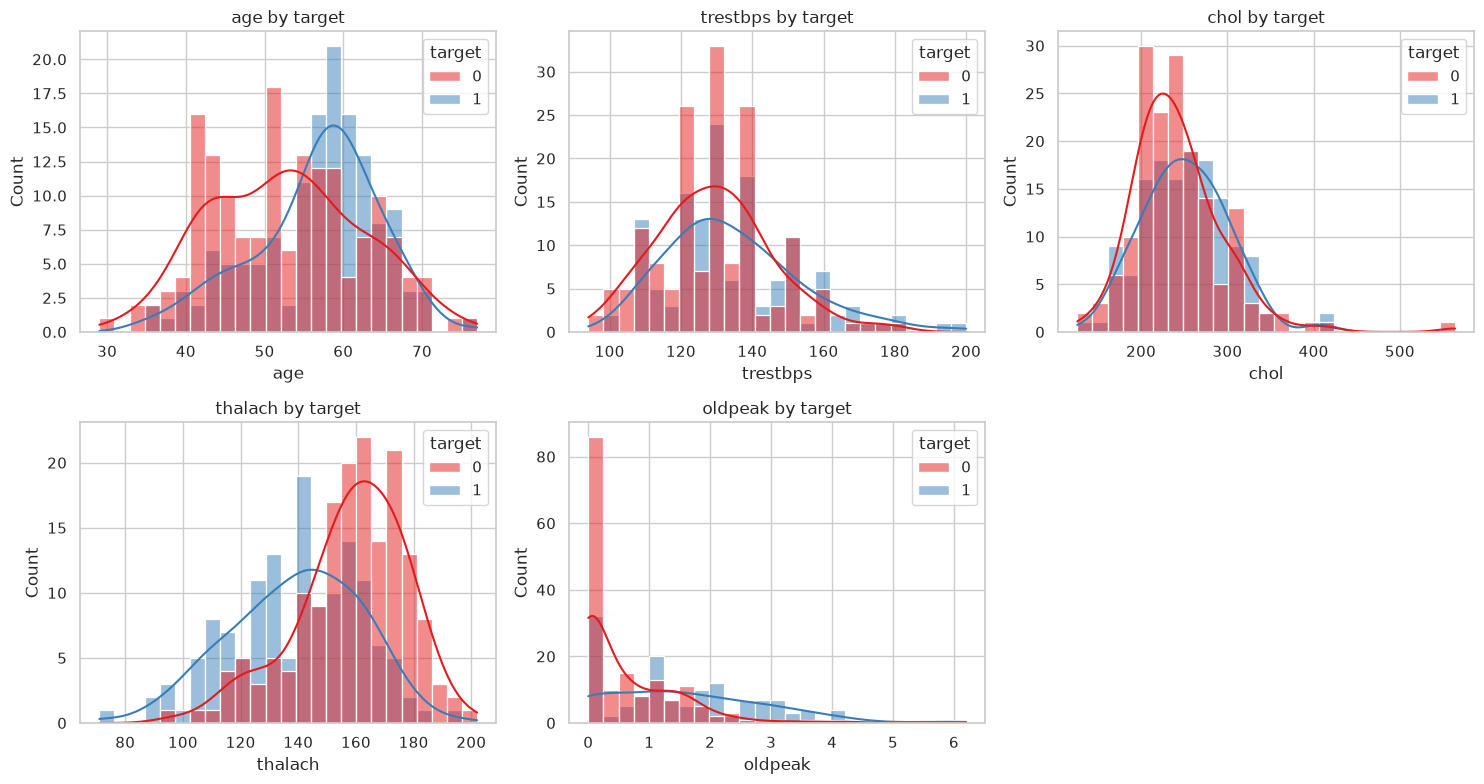

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, bins=25, ax=ax, palette="Set1")
    ax.set_title(f"{col} by target")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

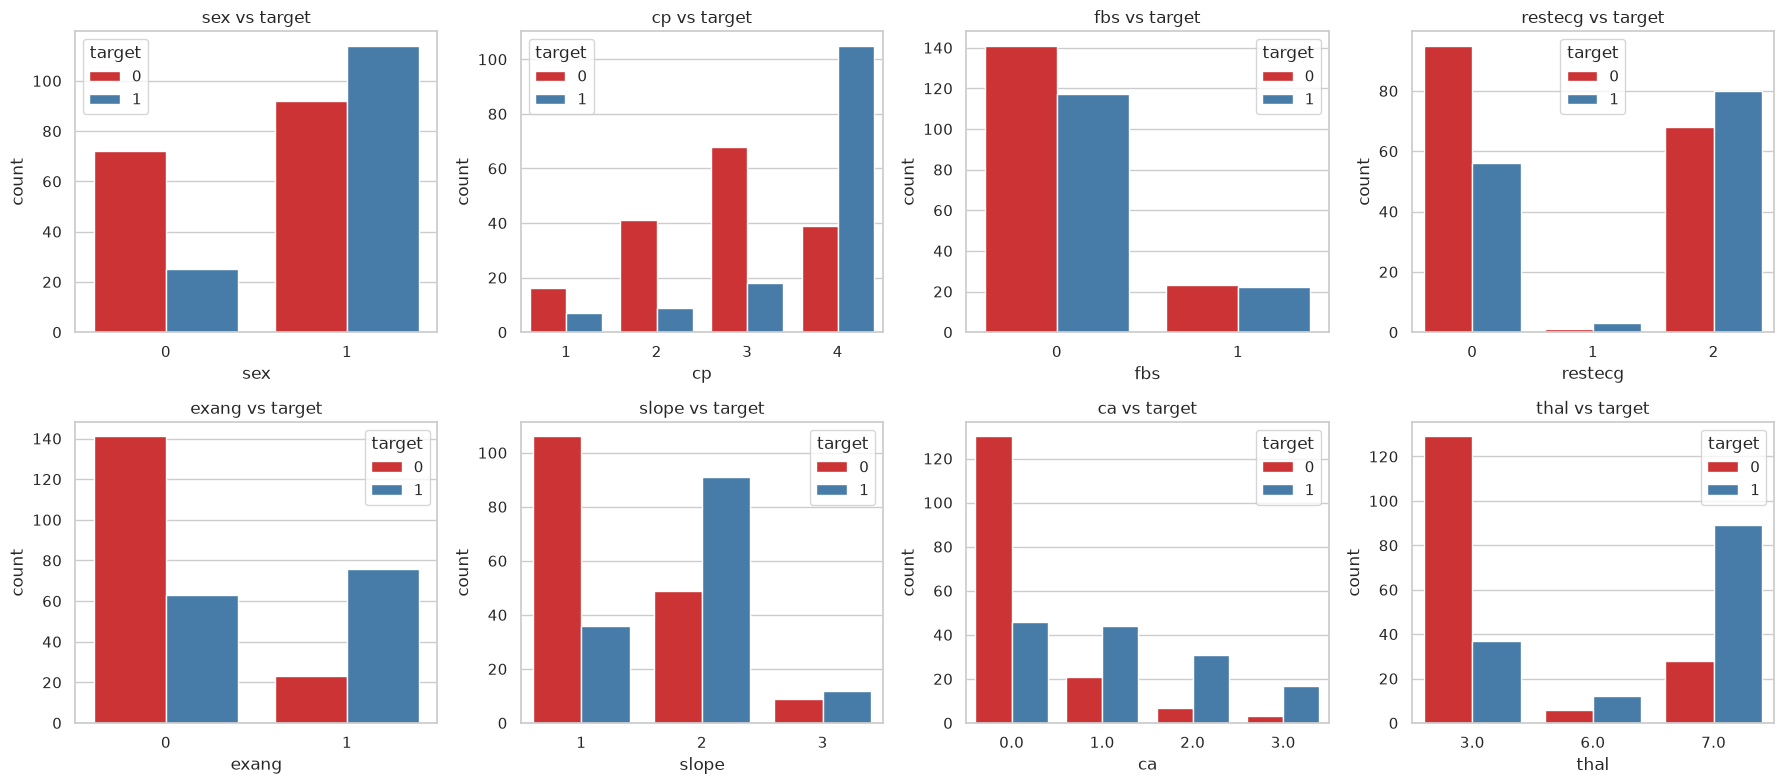

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, CATEGORICAL):
    sns.countplot(data=df, x=col, hue=TARGET, ax=ax, palette="Set1")
    ax.set_title(f"{col} vs target")
plt.tight_layout()
plt.savefig(FIG_DIR / "categorical_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

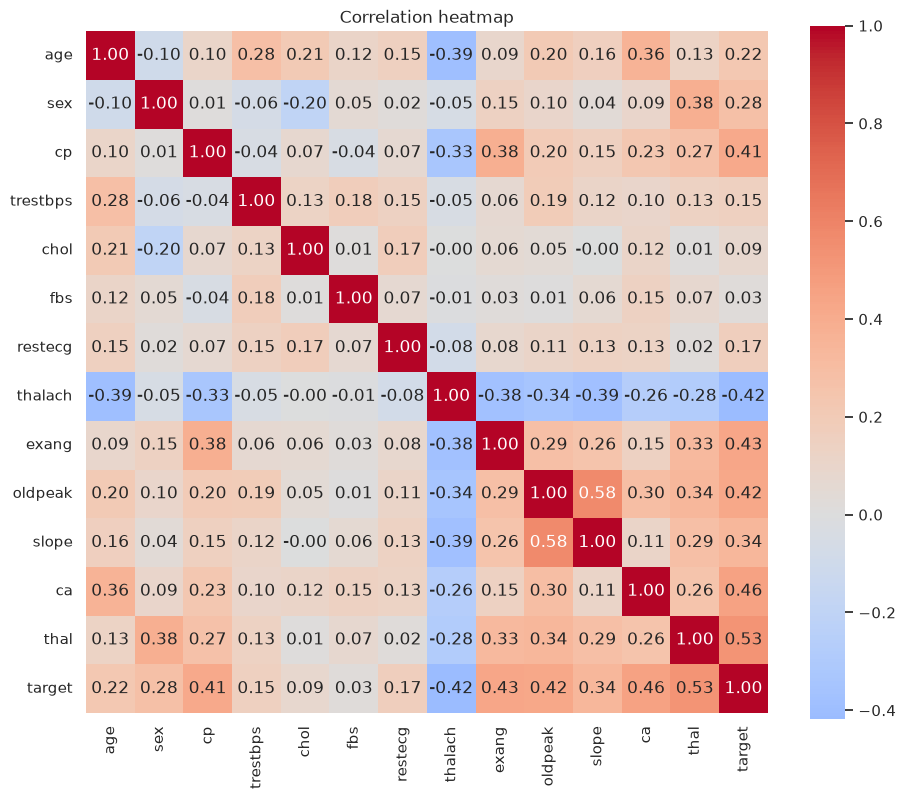

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
thalach    -0.417
Name: target, dtype: float64


In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

Strongest signals: thal (0.53), ca (0.46), exang (0.43), oldpeak (0.43), cp (0.41), and thalach (-0.42, negative: a higher maximum heart rate goes with lower risk).
Negligible: fbs (0.03) and chol (0.09). They look nearly useless on their own.

thal, cp, slope and restecg are category codes, not quantities. A Pearson correlation on them is only a rough guide, and the 3/6/7 coding of thal implies an order that doesn't exist. This is why we one-hot encode them.
A low correlation doesn't make a feature useless in a multivariate or non-linear model. Don't drop fbs or chol yet. We'll see how they behave in cross-validation.
Look at your heatmap for pairs of features that correlate strongly with each other (for example thalach with age). That matters for interpreting Logistic Regression coefficients.